# **Домашнее задание №1 (base)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;

**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–4 (EDA, модели, категориальные признаки, бизнес-метрика) — 5 баллов;
- Часть 5, оформление репозитория — 2 балла;
- Часть 6, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [1]:
# !pip install -q ydata-profiling "numpy<2.4"  # numba в Colab пока не поддерживает NumPy 2.4

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies

random.seed(42)
np.random.seed(42)

/tmp/ipykernel_30730/2223499982.py:6: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

`В процессе работы с данными мы сталкиваемся с разными случайностями. Например при разбиении данных на трейн и тест, когда делаем шафл, при делении на фолды и так далее. Фиксирование сида "фиксирует" случайность, вследствие чего эксперименты становятся воспроизводимыми`

# **Часть 1 | EDA и визуализация**

Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.5 балла)
- Визуализации признаков и их анализ (1 балл)

Всего за эту часть можно набрать 2.5 балла.

## **Простейший EDA и обработка признаков (1.5 балла)**

In [3]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.45 балла)**

Вы уже встречались с pandas в первой половине семестра. Теперь будем постоянно (кроме некоторых случаев) использовать его для анализа данных и наслаивать навыки. Выполните операции, направленные на практику основных действий с `pandas`:

**0.1 балла**
- [ ] Отобразите 30 случайных строк тренировочного датасета.
- [ ] Отобразите первые 5 и последние 5 объектов тестового датасета
- [ ] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения
- [ ] Посмотрите, есть ли в данных явные дубликаты


**0.2 балла**
Ответьте на вопросы:
- [ ] О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?
- [ ] Достаточно ли метода duplicated для анализа дубликатов? Почему?

**0.15 балла**
- [ ] Постройте дашборд, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling)

In [4]:
df_train.sample(n=30)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
6565,Renault KWID Climber 1.0 MT BSIV,2019,300000,35000,Petrol,Individual,Manual,First Owner,23.01 kmpl,999 CC,67 bhp,91Nm@ 4250rpm,5.0
2943,Maruti Wagon R LXI,2013,225000,58343,Petrol,Trustmark Dealer,Manual,First Owner,21.79 kmpl,998 CC,67.05 bhp,90Nm@ 3500rpm,5.0
2024,Hyundai i20 Asta 1.2,2013,360000,30000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
263,Hyundai i20 1.2 Asta,2010,300000,70000,Petrol,Individual,Manual,First Owner,17.0 kmpl,1197 CC,80 bhp,"11.4 kgm at 4,000 rpm",5.0
4586,Skoda Octavia L and K 1.9 TDI MT,2005,250000,120000,Diesel,Individual,Manual,Third Owner,16.4 kmpl,1896 CC,90 bhp,"21.4@ 1,900(kgm@ rpm)",5.0
4479,Maruti Ciaz ZXi,2016,700000,20000,Petrol,Individual,Manual,First Owner,20.73 kmpl,1373 CC,91.1 bhp,130Nm@ 4000rpm,5.0
4881,Hyundai Grand i10 1.2 Kappa Magna BSIV,2017,445000,27000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
3583,Ford Ecosport 1.5 DV5 MT Trend,2016,515000,68609,Diesel,Dealer,Manual,First Owner,22.7 kmpl,1498 CC,89.84 bhp,204Nm@ 2000-2750rpm,5.0
6361,Hyundai Verna 1.4 VTVT,2014,500000,33400,Petrol,Individual,Manual,First Owner,17.43 kmpl,1396 CC,105.5 bhp,135.3Nm@ 5000rpm,5.0
4108,Hyundai i20 Era 1.2,2015,490000,45900,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0


In [5]:
df_test

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Mahindra Xylo E4 BS IV,2010,229999,168000,Diesel,Individual,Manual,First Owner,14.0 kmpl,2498 CC,112 bhp,260 Nm at 1800-2200 rpm,7.0
1,Tata Nexon 1.5 Revotorq XE,2017,665000,25000,Diesel,Individual,Manual,First Owner,21.5 kmpl,1497 CC,108.5 bhp,260Nm@ 1500-2750rpm,5.0
2,Honda Civic 1.8 S AT,2007,175000,218463,Petrol,Individual,Automatic,First Owner,12.9 kmpl,1799 CC,130 bhp,172Nm@ 4300rpm,5.0
3,Honda City i DTEC VX,2015,635000,173000,Diesel,Individual,Manual,First Owner,25.1 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0
4,Tata Indica Vista Aura 1.2 Safire BSIV,2011,130000,70000,Petrol,Individual,Manual,Second Owner,16.5 kmpl,1172 CC,65 bhp,96 Nm at 3000 rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Hyundai i10 Magna 1.1L,2008,250000,100000,Petrol,Individual,Manual,Second Owner,19.81 kmpl,1086 CC,68.05 bhp,99.04Nm@ 4500rpm,5.0
996,Hyundai i20 2015-2017 Sportz 1.2,2017,440000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
997,Hyundai i20 Era Diesel,2009,340000,40000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
998,Hyundai i10 Asta,2012,350000,25000,Petrol,Individual,Manual,First Owner,20.36 kmpl,1197 CC,78.9 bhp,111.8Nm@ 4000rpm,5.0


In [6]:
df_train.isna().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,202
engine,202


In [7]:
df_test.isna().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,19
engine,19


In [8]:
df_train.duplicated().sum(), df_test.duplicated().sum()

(np.int64(985), np.int64(62))

О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?

__Ответ:__ Можно посмотреть какие колонки у нас есть в данных, можно посмотреть какие типы данных есть, то есть такой чисто визуальный анализ, ничего более

---

Достаточно ли метода duplicated для анализа дубликатов? Почему?

__Ответ:__ не совсем, поскольку мы смотрим полные дупликаты, но может быть такое, что значения регрессоров совпадают, а таргеты нет, это не очень хорошая ситуация, поскольку модель не сможет нормально обучиться на таких переменных, также это может означать, что различия в таргете обосновываются различиями в каких-то признаках, которые мы не учитываем.

In [9]:
profile = ProfileReport(df_train, title="Profiling Report")
profile.to_file("Profiling Report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:00<00:00, 15.94it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### **Задание 2 (0.5 балла)**

На прошлом шаге вы рассмотрели дубликаты. Однако дубликат может быть связан не только с полным повторением информации в нескольких строках, но и частичным. Например, объект мог быть внесён в базу данных с разным значением целевой переменной. В этом шаге займемся такими дублями!

**Ваши действия:**

- [ ] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.1 балла)
- [ ] Отобразите такие объекты (0.15 балла)
- [ ] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.15 балла)
- [ ]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.1 балла)


In [10]:
# your code here
df_train_wo_target = df_train.drop(columns=['selling_price'])
df_train_wo_target.duplicated().sum()

np.int64(1159)

In [11]:
df_train_wo_target[df_train_wo_target.duplicated() == True]

,name,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
254,Hyundai Grand i10 Sportz,2017,35000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,82 bhp,114Nm@ 4000rpm,5.0
258,Maruti Swift VXI,2012,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
268,Maruti Swift Dzire VXI,2014,70000,Petrol,Individual,Manual,Second Owner,19.1 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
324,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
325,Lexus ES 300h,2019,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...
6947,Chevrolet Spark 1.0 LS,2010,60000,Petrol,Individual,Manual,Second Owner,18.0 kmpl,995 CC,62 bhp,90.3Nm@ 4200rpm,5.0
6984,Ford Freestyle Titanium Plus Diesel BSIV,2018,24000,Diesel,Individual,Manual,First Owner,24.4 kmpl,1498 CC,98.63 bhp,215Nm@ 1750-3000rpm,5.0
6989,Maruti Swift Dzire VDI,2015,50000,Diesel,Individual,Manual,First Owner,26.59 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
6997,Tata Indigo CR4,2013,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [12]:
df_train = df_train.drop_duplicates(subset=df_train_wo_target.columns, keep='first')
df_train.reset_index(drop=True, inplace=True)

In [13]:
assert df_train.shape == (5840, 13)

Отлично! Мы избавились от маленьких и явных проблем. Теперь перейдем к более сложным недостаткам полученной таблицы.

### **Задание 3 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [ ] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [ ] Приведите тип данных к ``float``.
* [ ] Удалите столбец ``torque``


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.
- Столбец ``torque`` мы удаляем для простоты. В идеальном случае, его также стоило бы предобработать.

In [14]:
# your code here
cols_to_change = ['mileage', 'engine', 'max_power']
for col in cols_to_change:
  df_train[col] = df_train[col].str.split(' ').str[0]
  df_test[col] = df_test[col].str.split(' ').str[0]

  df_train[col] = pd.to_numeric(df_train[col], errors='ignore')
  df_test[col] = pd.to_numeric(df_test[col], errors='ignore')

del df_train['torque']
del df_test['torque']

/tmp/ipykernel_30730/2651132893.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train[col] = df_train[col].str.split(' ').str[0]
/tmp/ipykernel_30730/2651132893.py:7: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df_train[col] = pd.to_numeric(df_train[col], errors='ignore')
/tmp/ipykernel_30730/2651132893.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train[col] = pd.to_numeric

In [15]:
df_train[['mileage', 'engine', 'max_power']]

,mileage,engine,max_power
0,23.40,1248.0,74.00
1,21.14,1498.0,103.52
2,23.00,1396.0,90.00
3,16.10,1298.0,88.20
4,20.14,1197.0,81.86
...,...,...,...
5835,17.92,1086.0,62.10
5836,18.90,998.0,67.10
5837,18.50,1197.0,82.85
5838,16.80,1493.0,110.00


### **Задание 4 (0.15 балла)**

В Задании 1 мы обнаружили пропуски. Давайте избавимся от них.

**Шаг 1 (0.05 балла)**
- [ ] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось. Заполнение пропусков проводите для обоих наборов данных, если необходимо

**Важно!**

При заполнении пропусков и в тестовом, и тренировочном наборах данных вы определяетесь со стратегией предобработки пропущенных значений при потенциальной работе модели.

Так как в теоретическом случае вы не имеете доступа к тестовой выборке, то заполняемое значение (у нас — медиана) вы считаете по *тренировочному* набору данных и им же заполняете *тестовый*.

In [16]:
# your code here
for col in ['mileage', 'engine', 'max_power', 'seats']:
  df_train[col] = df_train[col].fillna(df_train[col].median())
  df_test[col] = df_test[col].fillna(df_train[col].median())

df_train.isna().sum(), df_test.isna().sum()

/tmp/ipykernel_30730/3375195364.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train[col] = df_train[col].fillna(df_train[col].median())


(name             0
 year             0
 selling_price    0
 km_driven        0
 fuel             0
 seller_type      0
 transmission     0
 owner            0
 mileage          0
 engine           0
 max_power        0
 seats            0
 dtype: int64,
 name             0
 year             0
 selling_price    0
 km_driven        0
 fuel             0
 seller_type      0
 transmission     0
 owner            0
 mileage          0
 engine           0
 max_power        0
 seats            0
 dtype: int64)

**Шаг 2 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [ ] Осуществите приведение столбцов к необходимому типу.

In [17]:
# your code here
df_train['engine'] = df_train['engine'].astype(int)
df_train['seats'] = df_train['seats'].astype(int)

df_test['engine'] = df_test['engine'].astype(int)
df_test['seats'] = df_test['seats'].astype(int)

/tmp/ipykernel_30730/296642658.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train['engine'] = df_train['engine'].astype(int)
/tmp/ipykernel_30730/296642658.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train['seats'] = df_train['seats'].astype(int)


### **Задание 5 (0.15 балла)**

Отлично! Мы провели "косметическую" предобработку и теперь готовы сделать важный шаг в контексте анализа данных. А именно — посмотреть на статистики!

**Ваша задача:**
- [ ] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [ ] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [ ] Сделайте вывод.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

**Примечание:**

Более корректно рассматривать статистики до заполнения пропусков и после, чтобы убедиться, что мы не внесли каких-либо серьезных сдвигов в изначальные распределения.

In [18]:
# your code here
df_train.describe(include='all')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
count,5840,5840.000000,5.840000e+03,5.840000e+03,5840,5840,5840,5840,5840.000000,5840.000000,5840.000000,5840.000000
unique,1924,NaN,NaN,NaN,4,3,2,5,NaN,NaN,NaN,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,NaN
freq,91,NaN,NaN,NaN,3177,5223,5336,3603,NaN,NaN,NaN,NaN
mean,NaN,2013.428425,5.229601e+05,7.395224e+04,NaN,NaN,NaN,NaN,19.430841,1429.448973,87.906371,5.426712
std,NaN,4.095622,5.354320e+05,6.007114e+04,NaN,NaN,NaN,NaN,3.985973,485.662834,31.640418,0.982344
min,NaN,1983.000000,2.999900e+04,1.000000e+00,NaN,NaN,NaN,NaN,0.000000,624.000000,0.000000,2.000000
25%,NaN,2011.000000,2.500000e+05,3.900000e+04,NaN,NaN,NaN,NaN,16.950000,1197.000000,68.000000,5.000000
50%,NaN,2014.000000,4.050000e+05,7.000000e+04,NaN,NaN,NaN,NaN,19.370000,1248.000000,81.860000,5.000000
75%,NaN,2017.000000,6.400000e+05,1.000000e+05,NaN,NaN,NaN,NaN,22.300000,1498.000000,99.000000,5.000000


In [19]:
df_test.describe(include='all')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
count,1000,1000.000000,1.000000e+03,1000.000000,1000,1000,1000,1000,1000.00000,1000.00000,1000.000000,1000.000000
unique,621,NaN,NaN,NaN,4,3,2,5,NaN,NaN,NaN,NaN
top,Maruti Alto 800 LXI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,NaN
freq,15,NaN,NaN,NaN,534,837,877,623,NaN,NaN,NaN,NaN
mean,NaN,2013.681000,6.179010e+05,71393.341000,NaN,NaN,NaN,NaN,19.33881,1454.87600,90.841670,5.403000
std,NaN,4.012149,7.585539e+05,48486.218662,NaN,NaN,NaN,NaN,3.95175,521.99574,34.893389,0.912921
min,NaN,1995.000000,3.100000e+04,1303.000000,NaN,NaN,NaN,NaN,0.00000,624.00000,34.200000,4.000000
25%,NaN,2011.000000,2.500000e+05,37000.000000,NaN,NaN,NaN,NaN,16.55000,1197.00000,69.000000,5.000000
50%,NaN,2014.000000,4.349990e+05,61500.000000,NaN,NaN,NaN,NaN,19.37000,1248.00000,82.425000,5.000000
75%,NaN,2017.000000,6.700000e+05,100000.000000,NaN,NaN,NaN,NaN,22.30000,1582.00000,102.000000,5.000000


Вывод - статистики +- похожи на трейне и тесте, это хорошо

In [20]:
# torque удалён в Задании 3, поэтому столбцов 12
assert df_train.shape == (5840, 12)

## **Визуализации (1 балл)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 6 (0.4 балла)**

Шаг 1.
- [ ] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [ ] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [ ] Постройте pairplot по тестовым данным
- [ ] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

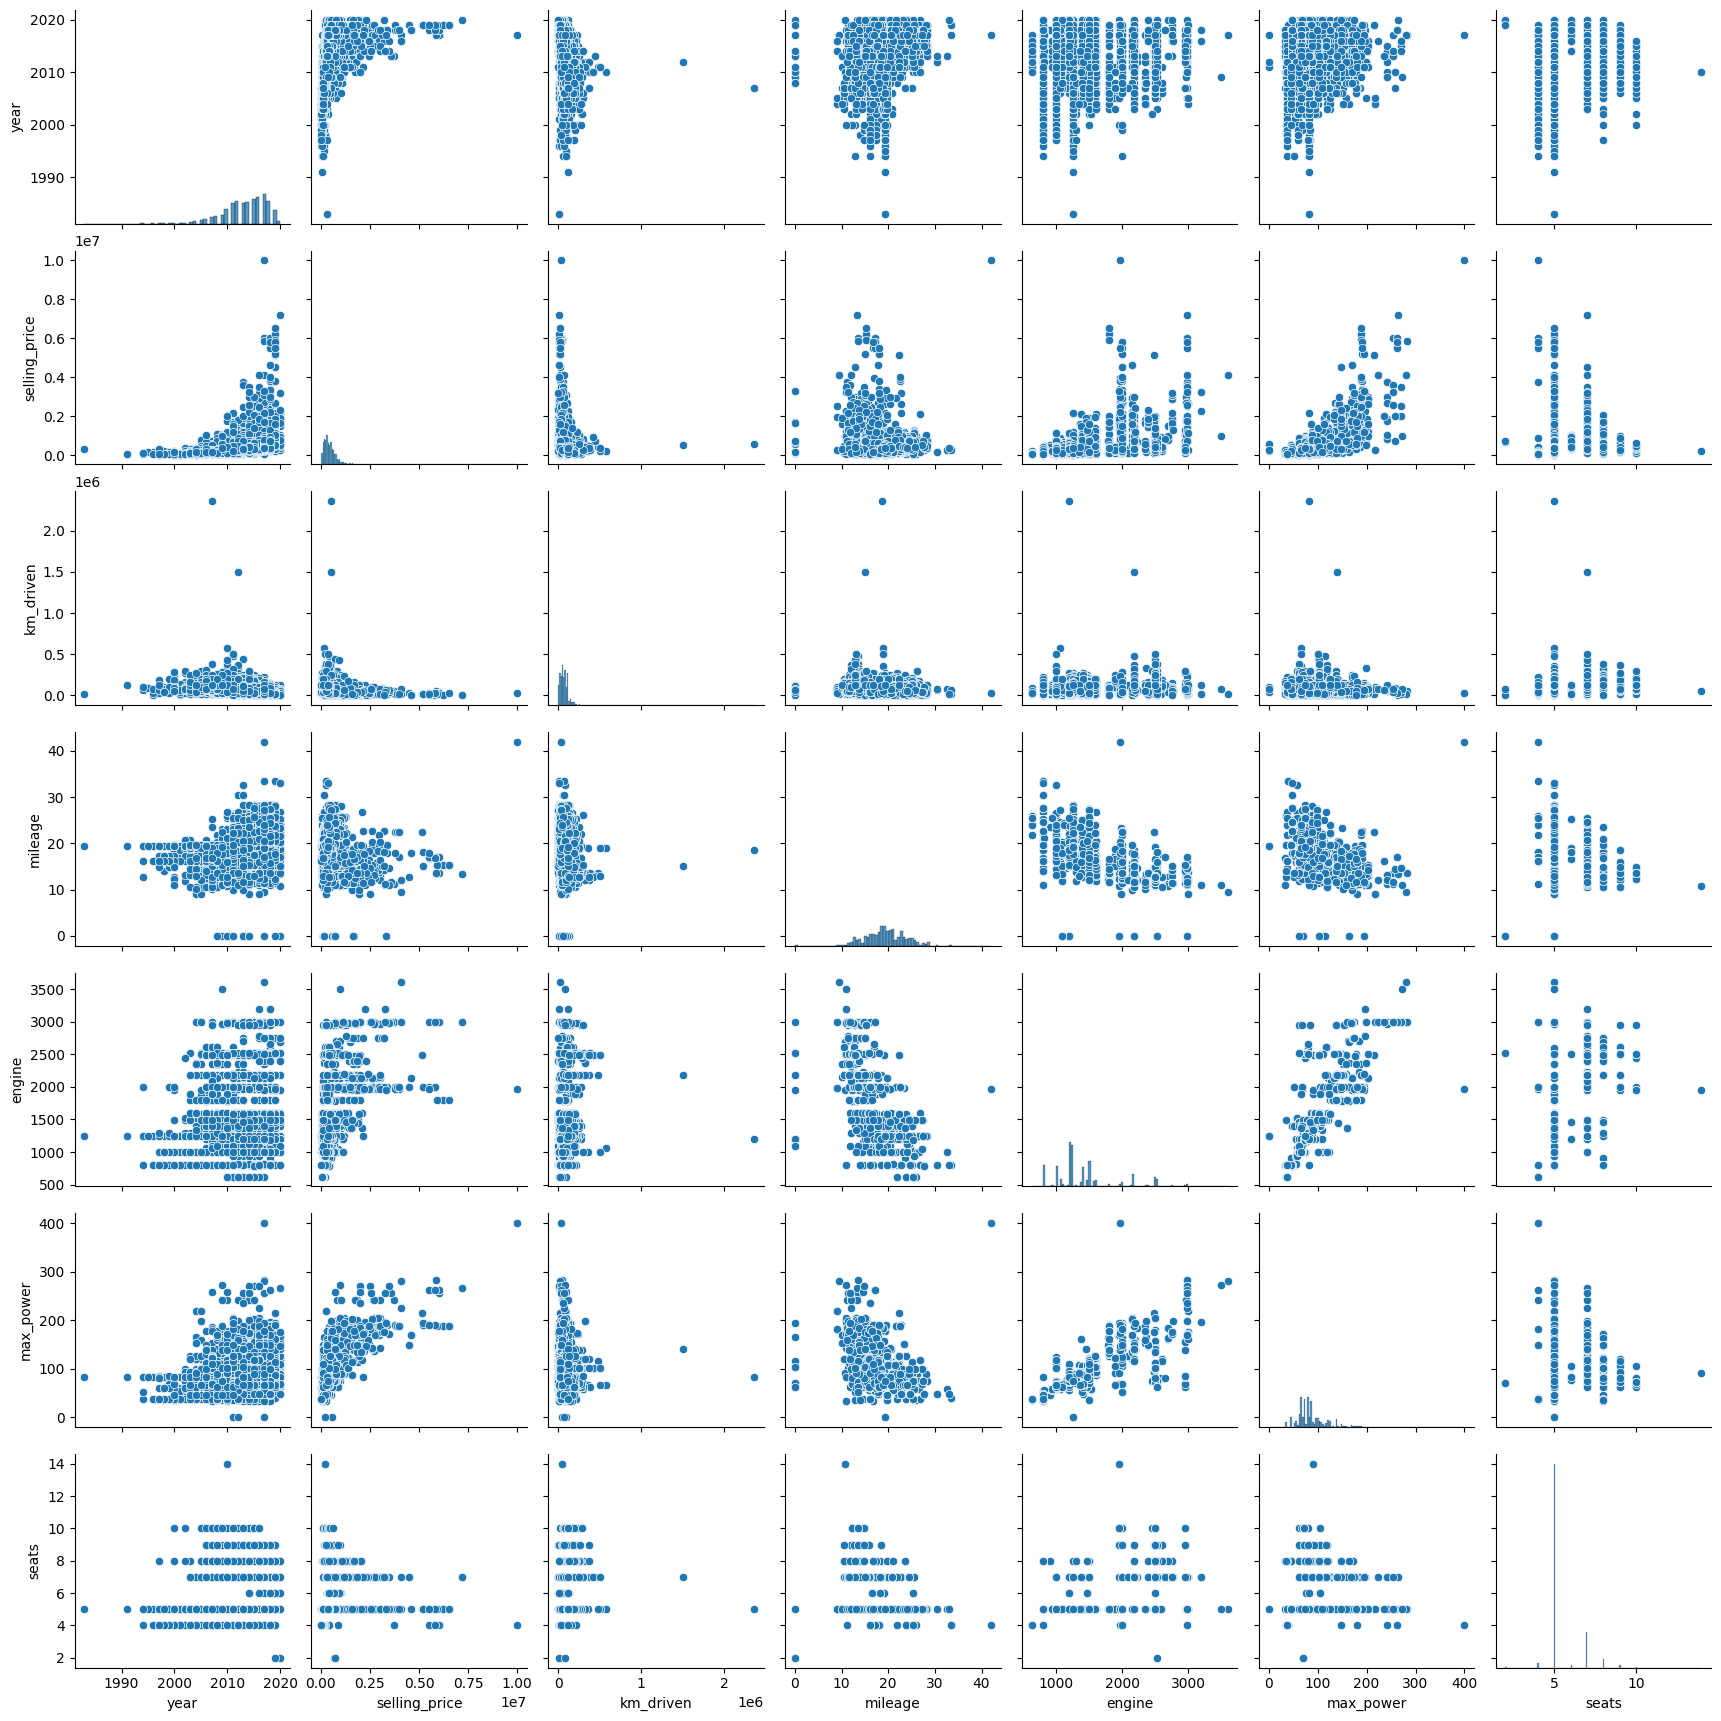

In [21]:
# your code here
num_cols = df_train.select_dtypes(include='number').columns

sns.pairplot(
    df_train,
    vars=num_cols,
    diag_kind='hist'
)
plt.show()

Можно ли предположить на основе распределений связь признаков с целевой переменной?

__Ответ:__ Честно говоря не уверен, так как диаграммы рассеяния не выглядят очевидными. Можно сказать, что есть положительная линейная взаимосвязь между ценой и максимальной мощностью, ценой и engine, вероятно есть положительная монотонная связь между ценой и годом, и отрицательная между ценой и km deiven.

---

 Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

 __Ответ:__ Вероятно milage отрицательно связан как с engine, так и с max_power, engine положительно связян с максимальной мощностью. Можно делать разные предположения, но мне лично кажется, что много удобней посмотреть коэффициенты корреляции.

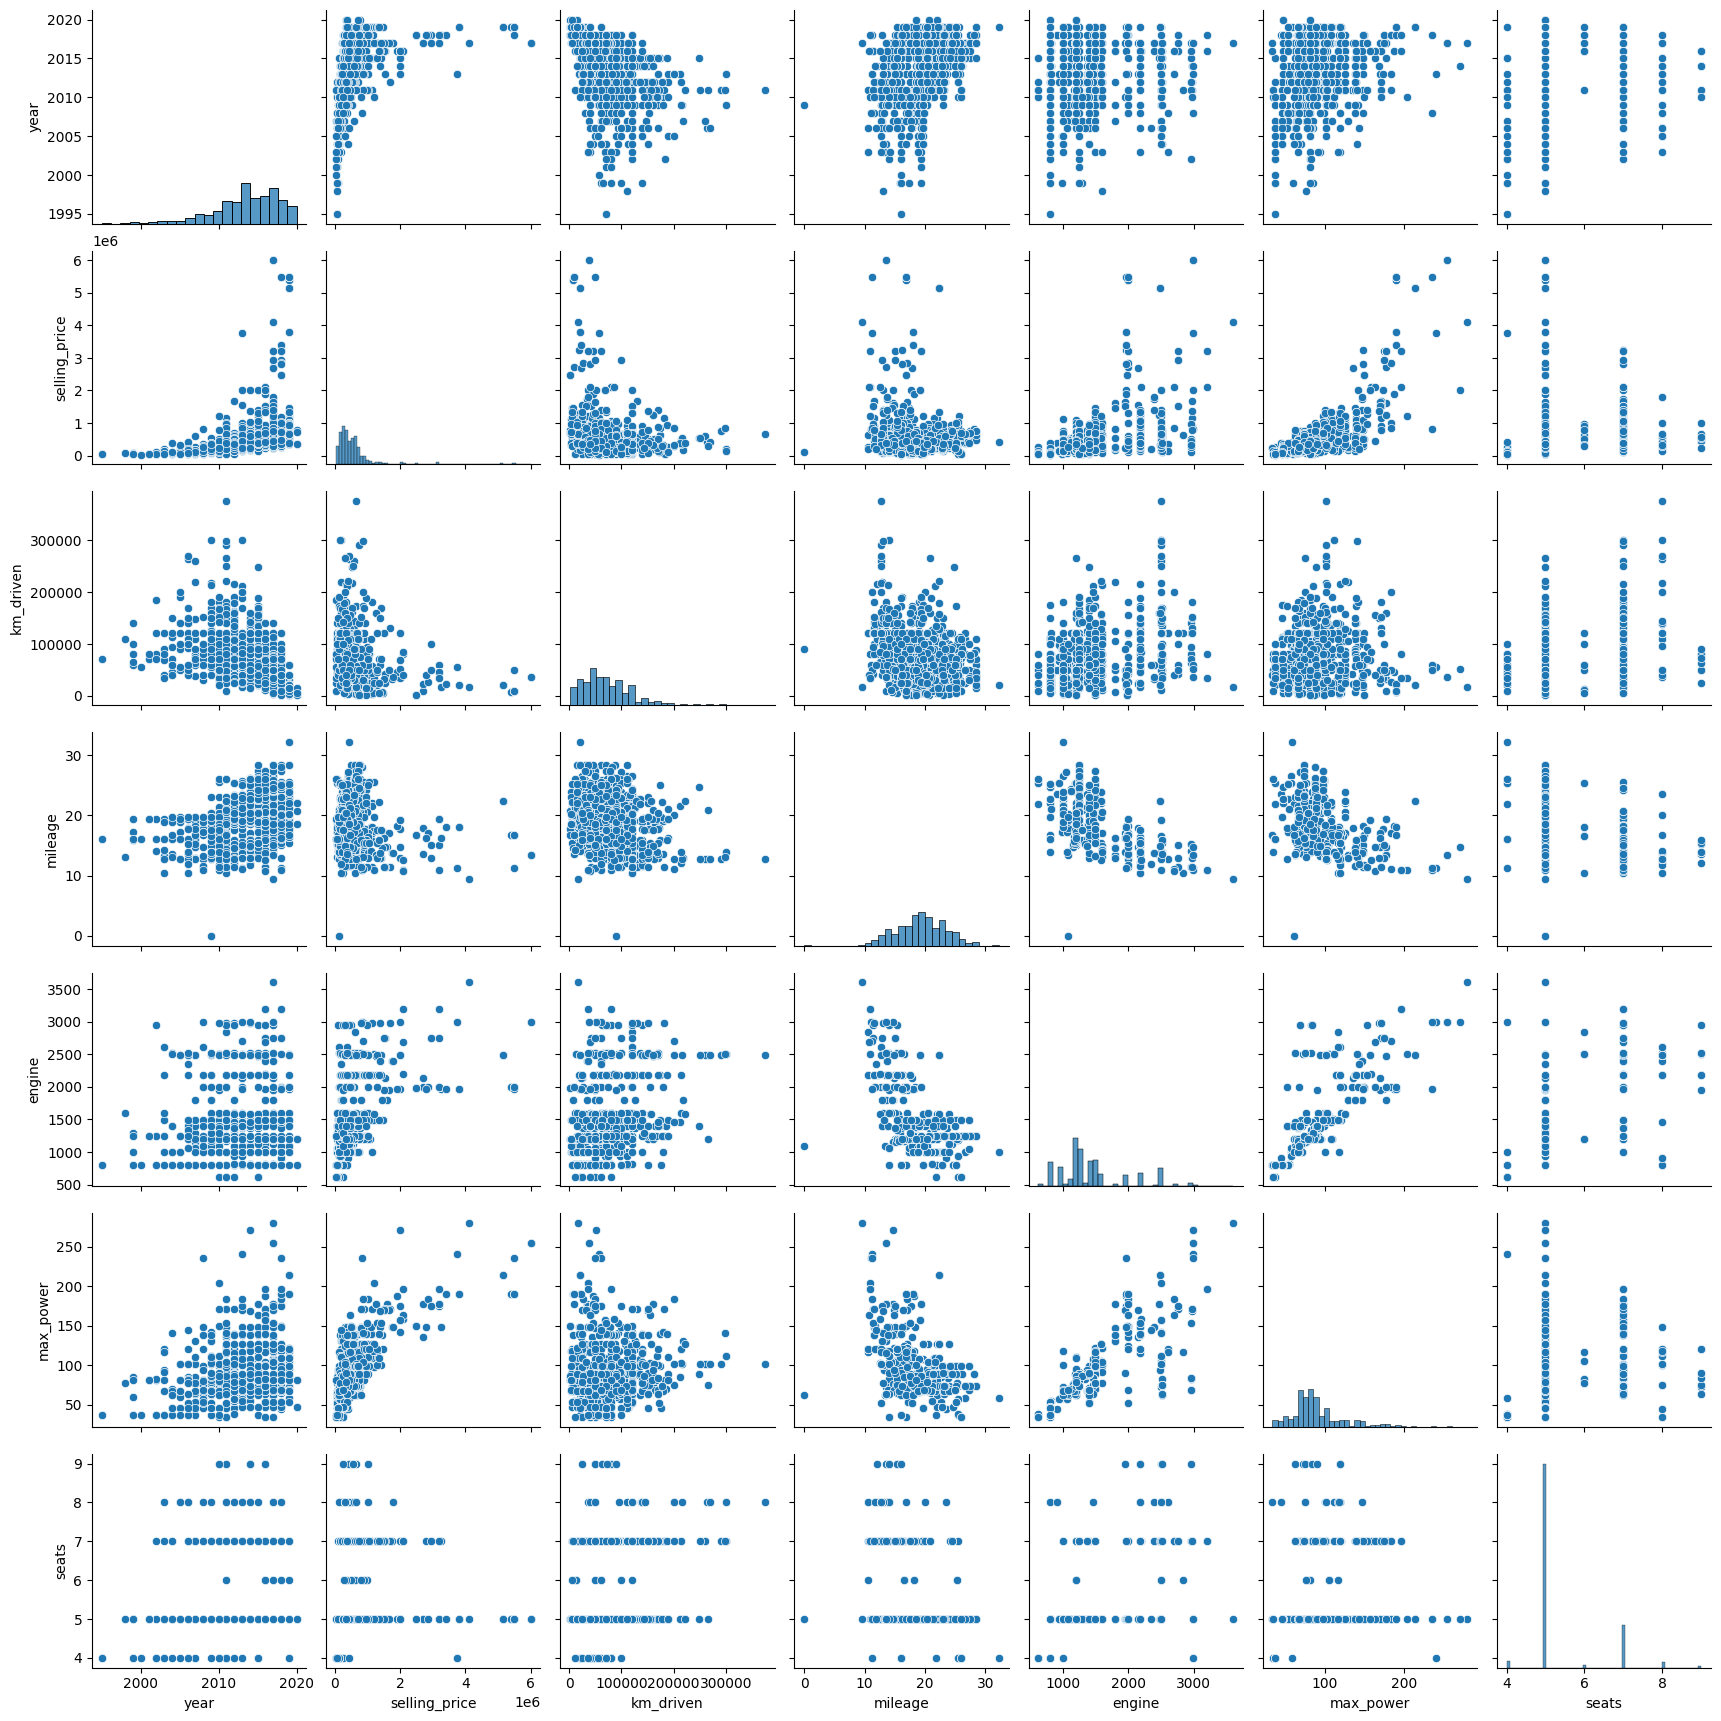

In [22]:
# your code here
num_cols = df_test.select_dtypes(include='number').columns

sns.pairplot(
    df_test,
    vars=num_cols,
    diag_kind='hist'
)
plt.show()

`Your answer here`
__Ответ:__ Ну может не идеально повторяются взаимосвязи, но мне кажется достаточно похожи

### **Задание 7 (0.35 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [ ] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [ ] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

<Axes: >

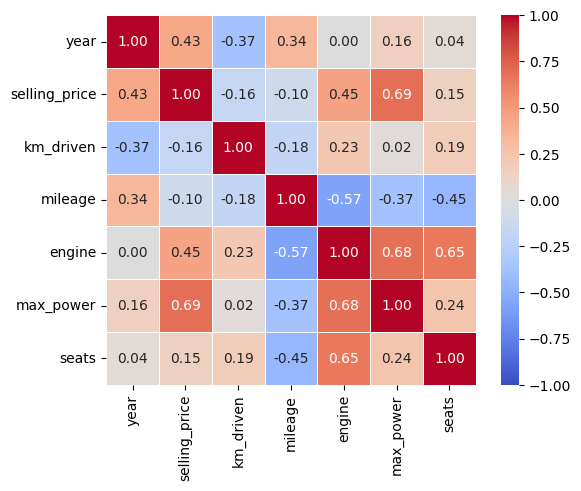

In [23]:
# your code here
sns.heatmap(
    data=df_train.corr(numeric_only=True),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
)

- [ ] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?

Какие 2 признака наименее скоррелированы между собой?
__Ответ:__ Year и engine (0.00)

---

Между какими наблюдается довольно сильная положительная линейная зависимость?
__Ответ:__ Max_power-selling_price, max_power-engine, seats-engine

---

Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?
__Ответ:__ Correlation is not causation! С точки зрения коэффициентов корреляции нельзя делать такие выводы, это лишь наша попытка объяснить, откуда может взятся такая корреляция. Мы можем говорить, что при изменении одного параметра, второй измениться в соответствии с коэффициентом, при прочих равных условиях. Если важна причинность, то это в causal inference

### **Задание 8 (0.25 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [ ] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

<Axes: xlabel='selling_price', ylabel='Count'>

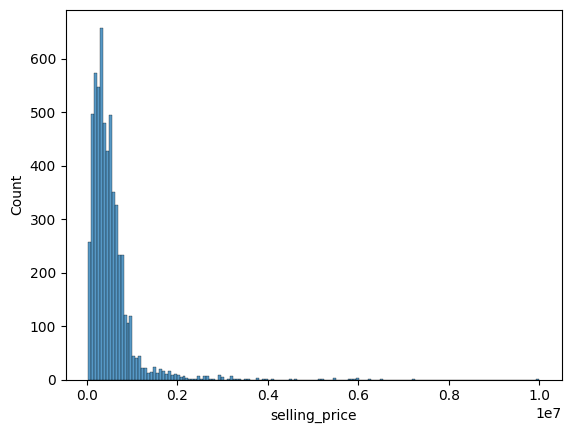

In [24]:
# your code here
sns.histplot(df_train['selling_price'])

<Axes: xlabel='count', ylabel='transmission'>

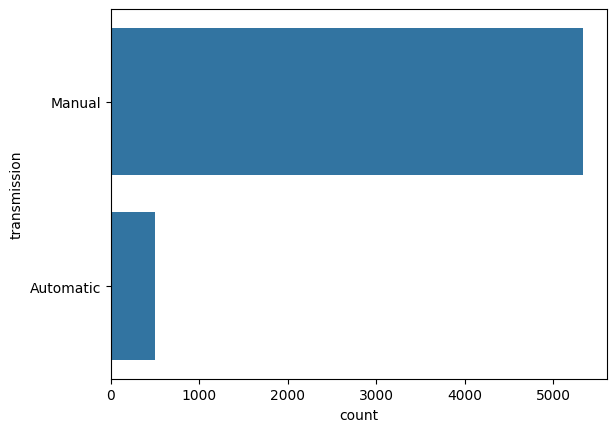

In [25]:
sns.countplot(df_train['transmission'])

<Axes: xlabel='count', ylabel='transmission'>

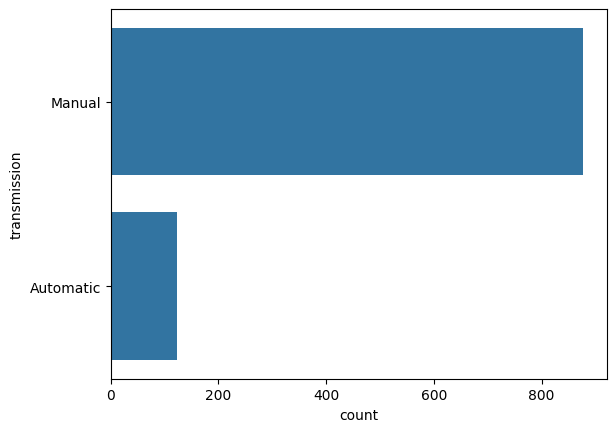

In [26]:
sns.countplot(df_test['transmission'])

__Почему важно:__ Неплохо было бы, чтобы целевая переменная была распределена нормально, в целом можно просто будет взять логарифм от целевой переменной, только не забыть преобразовать обратно. Второй график нужен для анализа наличия дисбаланса. Действительно, видим, что automatic годраздо менее представленный класс, однако распределение на трейне и на тесте +- похожее.

# **Часть 2 | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.25 балла.

### **Задание 9 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test при разбиении. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [27]:
df_train_continous = df_train[['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']]
df_test_continous = df_test[['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']]

In [28]:
y_train = df_train_continous['selling_price']
X_train = df_train_continous.drop(columns='selling_price')

In [29]:
# опишите выбранные вещественные признаки
['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
# В целом описывать особо нечего, все вещественные регрессоры, которые были в датасете

['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

In [30]:
y_test = df_test_continous['selling_price']
X_test = df_test_continous.drop(columns='selling_price')

### **Задание 10 (0.2 балла)**

Построим нашу первую модель!
- [ ] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [ ] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [31]:
# your code here
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
pred_train = lr.predict(X_train)
print('R2 test score', round(r2_score(y_test, pred_lr), 3))
print('MSE test', round(MSE(y_test, pred_lr)))
print(40*'=')
print('R2 train score', round(r2_score(y_train, pred_train), 3))
print('MSE train', round(MSE(y_train, pred_train)))

R2 test score 0.594
MSE test 233298779730
R2 train score 0.592
MSE train 116874153930


In [32]:
np.sqrt(MSE(y_train, pred_train))

np.float64(341868.6208619161)

Сам по себе r2 говорит, что модель предсказывает 59,4% вариации дисперсии целевой переменной, это неплохо для первого опыта, но и не очень хорошо. Можно сказать, что модель работает лучше, чем предсказание средним, то есть наивный прогноз мы обошли. МSE уже сложнее проинтерпретировать, так как он в квадратных у.е., но мы видим, что на тесте ошибка в +-2 раза больше, чем на трейне, то есть можно подозревать модель в переобучении. Однако $\sqrt{116874153930}=341868$, ошибка огромна.

### **Задание 11 (0.15 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [ ] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [33]:
# your code here
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
pred_lr_scaled = lr.predict(X_test_scaled)
pred_train = lr.predict(X_train_scaled)
print('R2 test score', round(r2_score(y_test, pred_lr_scaled), 3))
print('MSE test', round(MSE(y_test, pred_lr_scaled)))
print(40*'=')
print('R2 train score', round(r2_score(y_train, pred_train), 3))
print('MSE train', round(MSE(y_train, pred_train)))

R2 test score 0.594
MSE test 233298779730
R2 train score 0.592
MSE train 116874153930


Качество не изменилось, вероятно потому, что считается не градиентным спуском, а аналитической формулой, однако если смотреть сами коэффициенты, то они поменялись

### **Задание 12 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [ ] Какой признак оказался наиболее информативным в предсказании цены?

In [34]:
# your code here
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coef': lr.coef_
})

coef_df['abs_coef'] = coef_df['coef'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).drop(columns='abs_coef')

print(f'intercept_: {lr.intercept_:.4f}')
print(coef_df.to_string(index=False, float_format=lambda v: f'{v: .4f}'))

intercept_: 522960.0911
  feature         coef
max_power  322807.3533
     year  152772.5708
   engine   61178.4943
km_driven  -44158.8185
  mileage   28833.9258
    seats  -23209.1325


Больше всего влияет переменная max_power

### **Задание 13 (0.25 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [ ] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [ ] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [35]:
# your code here
lasso = Lasso()
lasso.fit(X_train_scaled, y_train)
pred_lasso = lasso.predict(X_test_scaled)
pred_train = lasso.predict(X_train_scaled)
print('R2 test score', round(r2_score(y_test, pred_lasso), 3))
print('MSE test', round(MSE(y_test, pred_lasso)))
print(40*'=')
print('R2 train score', round(r2_score(y_train, pred_train), 3))
print('MSE train', round(MSE(y_train, pred_train)))

R2 test score 0.594
MSE test 233299450599
R2 train score 0.592
MSE train 116874153940


Качество судя по r2 осталось таким же.

In [36]:
# your code here
lasso.coef_

array([152772.3902142 , -44157.68985794,  28832.04339588,  61173.66240922,
       322808.23691947, -23206.25564908])

Коэффициенты не занулились, но изменились. Возможно дело в масштабе таргета, и нужно брать большие $α$

### **Задание 14 Финальный рывок (0.5 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [37]:
# your code here
elasticnet = ElasticNet(l1_ratio=1)
parameters = {
    'alpha': [27500, 28000, 29000] # Такие странные значения, потому что перебирал разные варианты
}

gscv = GridSearchCV(elasticnet, parameters, cv=10, scoring='r2')
gscv.fit(X_train_scaled, y_train)


GridSearchCV(cv=10, estimator=ElasticNet(l1_ratio=1),
             param_grid={'alpha': [27500, 28000, 29000]}, scoring='r2')

In [38]:
# your code here
gscv.best_score_, gscv.best_estimator_, gscv.best_params_

(np.float64(0.5750179802274917),
 ElasticNet(alpha=27500, l1_ratio=1),
 {'alpha': 27500})

In [39]:
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coef': gscv.best_estimator_.coef_
})

coef_df['abs_coef'] = coef_df['coef'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).drop(columns='abs_coef')

print(f'intercept_: {gscv.best_estimator_.intercept_:.4f}')
print(coef_df.to_string(index=False, float_format=lambda v: f'{v: .4f}'))

intercept_: 522960.0911
  feature         coef
max_power  320989.2653
     year  145370.8213
km_driven  -15002.4772
  mileage       0.0000
   engine       0.0000
    seats      -0.0000


In [40]:
pred_gscv = gscv.best_estimator_.predict(X_test_scaled)

3 альфы * 10 фолдов = 30 моделей. Был выбран коэффициент регуляризации равный 27500. Занулились mileage, engine, seats.

**Ваша задача 2:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [41]:
# your code here
elasticnet = ElasticNet()
parameters = {
    'alpha': [0.0001, 0.001, 0.01, 0.1, 0.5, 1, 10, 20],
    'l1_ratio': [0.0, 0.2, 0.4, 0.6, 0.8, 1.]
}

gscv2 = GridSearchCV(elasticnet, parameters, cv=10, scoring='r2')
gscv2.fit(X_train_scaled, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.541e+14, tolerance: 1.247e+11 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.193e+14, tolerance: 1.564e+11 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_mode

GridSearchCV(cv=10, estimator=ElasticNet(),
             param_grid={'alpha': [0.0001, 0.001, 0.01, 0.1, 0.5, 1, 10, 20],
                         'l1_ratio': [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]},
             scoring='r2')

In [42]:
gscv2.best_score_, gscv2.best_estimator_, gscv2.best_params_

(np.float64(0.5761312700527227),
 ElasticNet(alpha=0.5, l1_ratio=0.8),
 {'alpha': 0.5, 'l1_ratio': 0.8})

In [43]:
pred_gscv2 = gscv2.best_estimator_.predict(X_test_scaled)

Было обучено 8* 6 *10=480 моделей. Были выбраны параметры: альфа=0,5, l1_ratio=0.8.

# **Часть 3 | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.75 балла.

**Задание 15 (0.1 балла)** Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

В этом домашнем задании мы предлагаем удалить его.

**Ваша задача:**
- [ ] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [ ] Удалите из них столбец `name`

In [44]:
# your code here
print(df_train['name'].nunique())
print(df_train.shape[0])

X_train_cat = df_train.drop(columns=['selling_price', 'name'])
X_test_cat = df_test.drop(columns=['selling_price', 'name'])

1924
5840


Получается у нас 1924 уникальных названия, а всего строк 5840, следовательно какие-то одинаковые марки и модели представлены несколько раз

В другом случае, конечно, мы могли бы предобработать данный столбец (например, выделить из названия марку автомобиля). В этом задании этого делать не нужно.

In [45]:
assert X_train_cat.shape == (5840, 10)

In [46]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840
unique,4,3,2,5
top,Diesel,Individual,Manual,First Owner
freq,3177,5223,5336,3603


### **Задание 16 (0.4 балла)**

- [ ] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования. Обратите внимание, что во избежание мультиколлинеарности следует избавиться от одного из полученных столбцов при кодировании каждого признака методом OneHot.

In [47]:
# your code here
ohe = OneHotEncoder(drop='first', sparse_output=False)
ohe.set_output(transform='pandas')
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']
ohe.fit_transform(X_train_cat[['fuel', 'seller_type', 'transmission', 'owner']]).head()
ohe.transform(X_test_cat[['fuel', 'seller_type', 'transmission', 'owner']])

,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
995,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
996,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
997,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
998,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


### **Задание 17 (0.25 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [ ] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [ ] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [48]:
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']

ohe = OneHotEncoder(drop='first', sparse_output=False)
ohe.set_output(transform='pandas')

ohe_train = ohe.fit_transform(X_train_cat[cat_cols])
ohe_test  = ohe.transform(X_test_cat[cat_cols])

X_train_full = pd.concat([X_train_cat.reset_index(drop=True),
                          ohe_train.reset_index(drop=True)], axis=1)
X_test_full  = pd.concat([X_test_cat.reset_index(drop=True),
                          ohe_test.reset_index(drop=True)], axis=1)

X_train_full.drop(columns=['fuel', 'seller_type', 'transmission', 'owner', 'seats'], inplace=True)
X_test_full.drop(columns=['fuel', 'seller_type', 'transmission', 'owner', 'seats'], inplace=True)

scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_full[['year', 'km_driven', 'mileage', 'engine', 'max_power']])
X_test_num = scaler.transform(X_test_full[['year', 'km_driven', 'mileage', 'engine', 'max_power']])

X_train_full_scaled = np.hstack([X_train_num, ohe_train.values])
X_test_full_scaled  = np.hstack([X_test_num,  ohe_test.values])

In [49]:
# your code here
ridge = Ridge()
params = {
    'alpha': [7.6, 7.8, 7.9] # Я немного поперебирал варианты
}
gs = GridSearchCV(ridge, params, cv=10, scoring='r2')
gs.fit(X_train_full_scaled, y_train)

GridSearchCV(cv=10, estimator=Ridge(), param_grid={'alpha': [7.6, 7.8, 7.9]},
             scoring='r2')

In [50]:
gs.best_score_, gs.best_estimator_, gs.best_params_

(np.float64(0.6221066626930929), Ridge(alpha=7.8), {'alpha': 7.8})

In [51]:
pred_gs = gs.best_estimator_.predict(X_test_full_scaled)
print(round(r2_score(y_test, pred_gs), 3))

0.645


Да, добавление категориальных фичей помогло улучшить качество модели.

# **Часть 4 | Бизнесовая (0.5 балла)**

### **Задание 18 (0.5 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metric}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [ ] Реализуйте метрику `business_metric`
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [52]:
def business_metric(y_true, y_pred):
    # your code here
    return np.mean((abs(y_pred - y_true) / y_true) <= 0.1)

print('business_metric linear regression', business_metric(y_test, pred_lr))
print('business_metric linear regression scaled', business_metric(y_test, pred_lr_scaled))
print('business_metric Lasso(alpha=1)', business_metric(y_test, pred_lasso))
print('business_metric Lasso(alpha=27500)', business_metric(y_test, pred_gscv))
print('business_metric Ridge(alpha=7.8)', business_metric(y_test, pred_gs))
print('business_metric ElasticNet(alpha=0.5, l1_ratio=0.8)', business_metric(y_test, pred_gscv2))


business_metric linear regression 0.227
business_metric linear regression scaled 0.227
business_metric Lasso(alpha=1) 0.227
business_metric Lasso(alpha=27500) 0.234
business_metric Ridge(alpha=7.8) 0.247
business_metric ElasticNet(alpha=0.5, l1_ratio=0.8) 0.241


Лучшее качество на бизнес метрике показала Ridge регрессия с alpha=7.8, следовательно она лучше всего решает задачу бизнеса.

# **Часть 5 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

In [53]:
import pickle
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

num_cols = ['year', 'km_driven', 'mileage', 'engine', 'max_power']
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']

prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
])

final_model = Pipeline([
    ('prep', prep),
    ('ridge', Ridge(alpha=gs.best_params_['alpha'])),
])
final_model.fit(X_train_cat, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['year', 'km_driven',
                                                   'mileage', 'engine',
                                                   'max_power']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['fuel', 'seller_type',
                                                   'transmission', 'owner',
                                                   'seats'])])),
                ('ridge', Ridge(alpha=7.8))])

In [54]:
with open('model.pickle', 'wb') as f:
    pickle.dump(final_model, f)

with open('model.pickle', 'rb') as f:
    loaded = pickle.load(f)

# **<font color="green">Часть 6 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 5 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 5 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.